Saving IMDB Dataset.csv to IMDB Dataset.csv
Dataset Shape: (50000, 2)
Epoch 1/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 22s 78ms/step - accuracy: 0.7945 - loss: 0.4361 - val_accuracy: 0.8593 - val_loss: 0.3333
Epoch 2/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.8789 - loss: 0.2926 - val_accuracy: 0.8606 - val_loss: 0.3284
Epoch 3/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 75ms/step - accuracy: 0.8960 - loss: 0.2576 - val_accuracy: 0.8549 - val_loss: 0.3389
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8573 - loss: 0.3279

Test Loss: 0.3279341161251068
Test Accuracy: 85.72999835014343 %


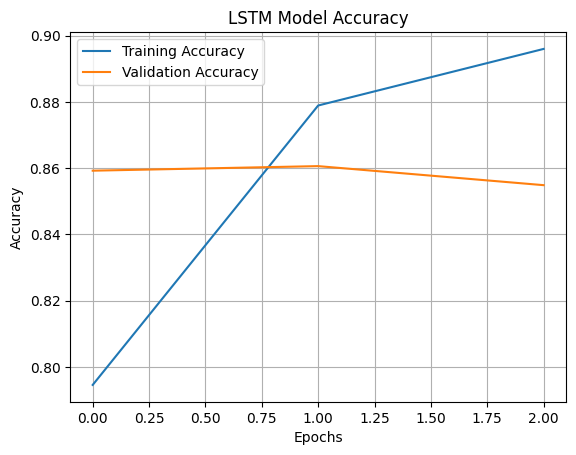

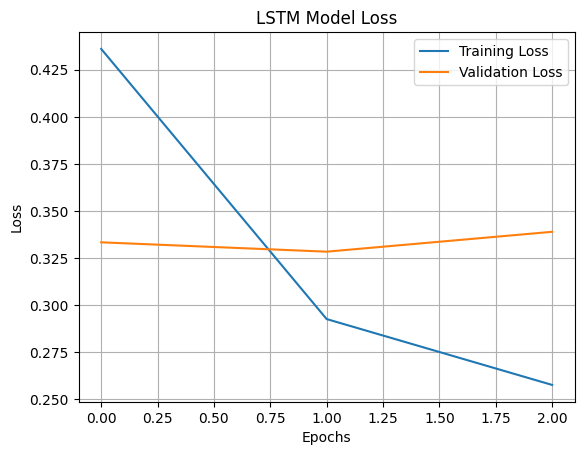

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step

Review: I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam's ev
Predicted: Negative
Actual: Positive

Review: Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many different countries as you ca
Predicted: Positive
Actual: Positive

Review: The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by Seagal's driving, but tha
Predicted: Negative
Actual: Negative

Review: Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, yet elegant. She puts on 
Predicted:

In [11]:
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import files
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# 1. Upload dataset
uploaded = files.upload()

# 2. Load dataset
data = pd.read_csv("IMDB Dataset.csv")

X = data["review"].astype(str)
y = data["sentiment"].map({"positive": 1, "negative": 0})

print("Dataset Shape:", data.shape)

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Save original test reviews
X_test_original = X_test.copy()

# 4. Tokenization and padding
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(X_train)

X_train = pad_sequences(
    tokenizer.texts_to_sequences(X_train), maxlen=100
)

X_test = pad_sequences(
    tokenizer.texts_to_sequences(X_test), maxlen=100
)

# 5. Build LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(5000, 32),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# 6. Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 7. Train model
history = model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.2
)

# 8. Evaluate model
loss, acc = model.evaluate(X_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", acc * 100, "%")

# 9. Plot accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.grid()
plt.show()

# 10. Plot loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("LSTM Model Loss")
plt.legend()
plt.grid()
plt.show()

# 11. Predict 5 example reviews
predictions = model.predict(X_test[:5])

for i in range(5):
    print("\nReview:", X_test_original.iloc[i][:200])

    print("Predicted:",
          "Positive" if predictions[i][0] >= 0.5 else "Negative")

    print("Actual:",
          "Positive" if y_test.iloc[i] == 1 else "Negative")

print("\nPROGRAM COMPLETED")

In [10]:
!pip install -q kaggle
!kaggle datasets download -d lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

Dataset URL: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
License(s): other
100% 25.7M/25.7M [00:01<00:00, 21.8MB/s]

